In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## Load data

In [2]:
# Monthly series
svar = pd.read_csv('data/svar_data.csv', index_col='observation_date', parse_dates=True)
svar = svar.rename(columns={'WPSID62': 'PCOM'})

# Weekly series
nfci_weekly = pd.read_csv('data/NFCI.csv', index_col='observation_date', parse_dates=True)
nfci_monthly = nfci_weekly.resample('MS').mean()

# Merge
df = svar.join(nfci_monthly, how='inner')
df = df.loc[:'2019'] # drop post-2020 data

# Transform to logs
for var in ['CPIAUCSL', 'INDPRO', 'PCOM']:
    df[f'l_{var}'] = 100 * np.log(df[[var]])

## SVAR

In [3]:
# Estimate VAR
order = ['l_INDPRO', 'UNRATE', 'l_CPIAUCSL', 'l_PCOM', 'FEDFUNDS', 'NFCI']
nlag = 12

model = sm.tsa.VAR(df[order])
res = model.fit(maxlags=nlag, ic=None)

c:\Users\mikkelpm\AppData\Local\anaconda3\envs\ecma31150\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


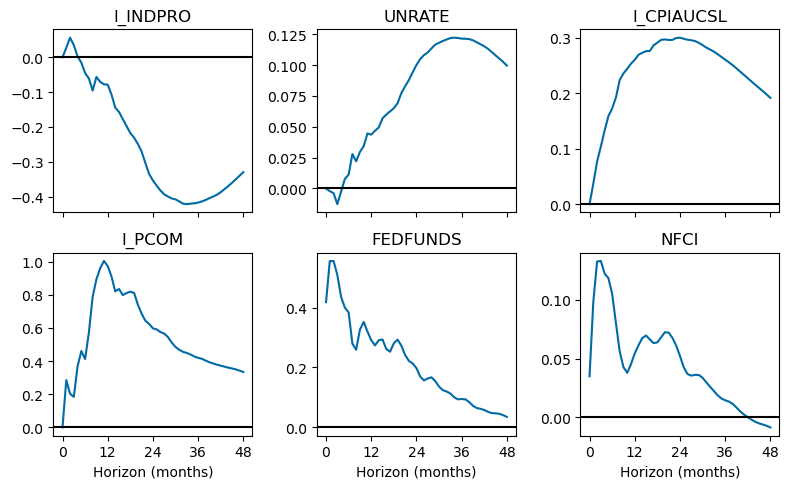

In [4]:
# Cholesky-identified IRFs
max_horizon = 48
irf = res.irf(max_horizon)

ffr_index = res.names.index('FEDFUNDS')
horizons = np.arange(irf.orth_irfs.shape[0])

fig, axes = plt.subplots(2, 3, figsize=(8, 5), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.plot(horizons, irf.orth_irfs[:, i, ffr_index])
    ax.axhline(0, color='black')
    ax.set_title(res.names[i])
    ax.set_xticks(range(0, max_horizon + 1, 12))
for ax in axes[-1, :]:
    ax.set_xlabel('Horizon (months)')
plt.tight_layout()
fig.savefig('output/mpshock_irf.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


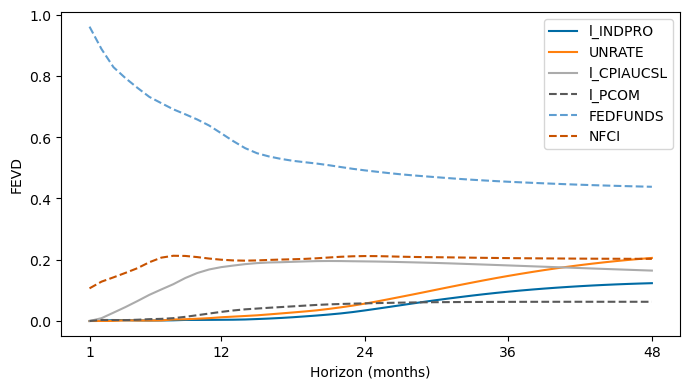

In [5]:
# FEVD
fevd = res.fevd(max_horizon)

fig, ax = plt.subplots(figsize=(7, 4))
for i, name in enumerate(res.names):
    ls = '--' if i >= 3 else '-'
    ax.plot(horizons[1:], fevd.decomp[i, :, ffr_index], label=name, linestyle=ls)
ax.set_xlabel('Horizon (months)')
ax.set_ylabel('FEVD')
ax.set_xticks([1] + list(range(12, max_horizon + 1, 12)))
ax.legend()
plt.tight_layout()
fig.savefig('output/mpshock_fevd.eps')
plt.show()

## SVAR with proxy (internal instrument)

In [6]:
# Load Bauer & Swanson (2023) monetary policy shock
mps = pd.read_csv('data/bauer_swanson_2023.csv')
mps.index = pd.to_datetime(mps[['Year', 'Month']].assign(Day=1))

df_mps = df.join(mps[['MPS_ORTH']], how='inner')

# Order shock first in SVAR
model_mps = sm.tsa.VAR(df_mps[['MPS_ORTH'] + order])
res_mps = model_mps.fit(maxlags=12, ic=None)

c:\Users\mikkelpm\AppData\Local\anaconda3\envs\ecma31150\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


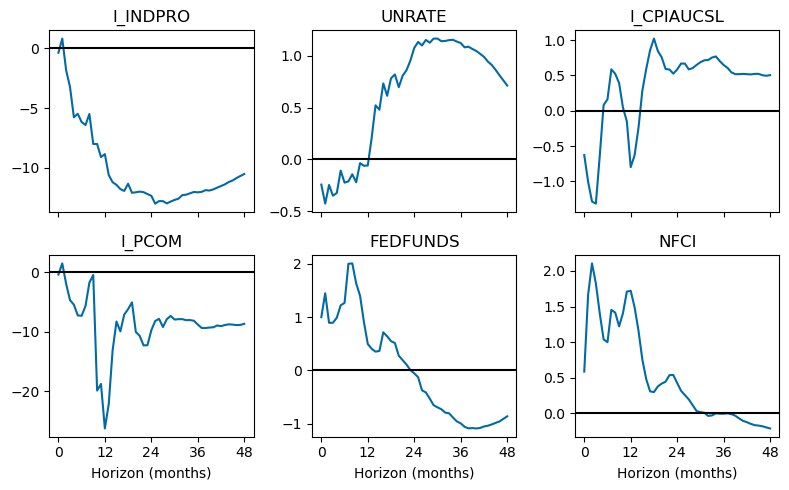

In [7]:
# Un-normalized IRFs
irf_mps = res_mps.irf(max_horizon)

# Unit effect normalization
mps_index = 0 # proxy ordered first
ffr_index_new = res_mps.names.index('FEDFUNDS')
ffr_impact = irf_mps.orth_irfs[0, ffr_index_new, mps_index]
irf_mps_normalized = irf_mps.orth_irfs[:, :, mps_index] / ffr_impact

# Plot
fig, axes = plt.subplots(2, 3, figsize=(8, 5), sharex=True)
for ax, name in zip(axes.flat, order):
    j = res_mps.names.index(name)
    ax.plot(horizons, irf_mps_normalized[:, j])
    ax.axhline(0, color='black')
    ax.set_title(name)
    ax.set_xticks(range(0, max_horizon + 1, 12))
for ax in axes[-1, :]:
    ax.set_xlabel('Horizon (months)')
plt.tight_layout()
fig.savefig('output/mpshock_proxy_irf.eps')
plt.show()

## Comparison with LP

In [8]:
def local_projection(df, outcome, shock, controls, max_horz):
    """Local projection IRF with SE"""
    irf = np.empty(max_horz + 1)
    se  = np.empty(max_horz + 1)
    for h in range(max_horz + 1):
        y = df[outcome].shift(-h)
        X = sm.add_constant(df[[shock] + controls])
        reg = sm.OLS(y, X, missing='drop').fit(cov_type='HC1')
        irf[h] = reg.params[shock]
        se[h]  = reg.bse[shock]
    return irf, se

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


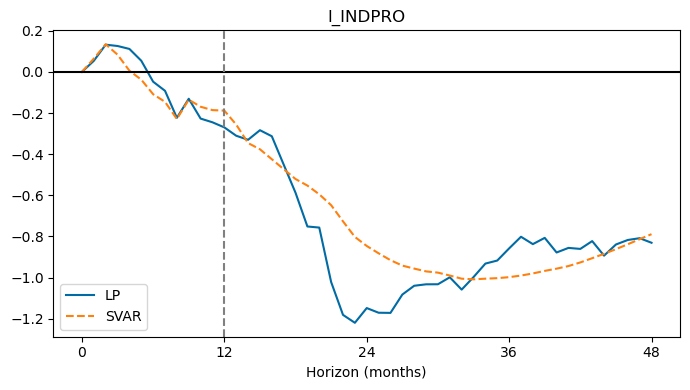

In [9]:
# Lags of all VAR variables (matching SVAR lag length)
df_lp = df[order].copy()
df_lp = df_lp.assign(**{
    f'{var}_lag{l}': df_lp[var].shift(l)
    for var in order for l in range(1, nlag + 1)
})
lag_cols = [f'{var}_lag{l}' for var in order for l in range(1, nlag + 1)]

# Contemporaneous controls = variables ordered before FFR
contemp_controls = order[:ffr_index]

# LP estimate
outcome_var = 'l_INDPRO'
irf_lp, _ = local_projection(df_lp, outcome_var, 'FEDFUNDS',
                             contemp_controls + lag_cols, max_horizon)

# Analogous SVAR IRF, unit effect normalization
outcome_var_index = res.names.index(outcome_var)
ffr_impact_svar = irf.orth_irfs[0, ffr_index, ffr_index]
irf_svar = irf.orth_irfs[:, outcome_var_index, ffr_index] / ffr_impact_svar

# Plot
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(horizons, irf_lp, label='LP')
ax.plot(horizons, irf_svar, label='SVAR', linestyle='--')
ax.axhline(0, color='black')
ax.axvline(nlag, color='gray', linestyle='--')
ax.set_title(outcome_var)
ax.set_xlabel('Horizon (months)')
ax.set_xticks(range(0, max_horizon + 1, 12))
ax.legend()
plt.tight_layout()
fig.savefig('output/mpshock_lp_svar.eps')
plt.show()